# Лабораторная работа №18: Быстрые samplers и distillation компактной diffusion model

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Переиспользовать checkpoint lab 17.
- Сравнить DDPM, DDIM и дополнительный solver.
- Обучить compact student и построить Pareto frontier.

## Теоретическая часть

DDIM использует тот же denoiser, но может идти по сокращённой последовательности timesteps детерминированно. Distillation обучает student воспроизводить несколько teacher steps одним шагом. Сравнение строится при одинаковых initial noise и labels.


DDIM вычисляет x̂0 и делает детерминированный переход между точками ᾱ. DPM-Solver++ использует тот же обученный ε-предсказатель. Progressive distillation аппроксимирует двумя teacher-переходами один student-переход; teacher заморожен.

Детерминированный DDIM-переход: $\hat x_0=(x_t-\sqrt{1-\bar\alpha_t}\hat\epsilon)/\sqrt{\bar\alpha_t}$, $x_s=\sqrt{\bar\alpha_s}\hat x_0+\sqrt{1-\bar\alpha_s}\hat\epsilon$. При конечном $s=-1$ полагаем $\bar\alpha_{-1}=1$.

### Экспериментальный протокол

Обязательная зависимость — реально обученные веса ddpm.pt, classifier.pt и classifier_validation.json из lab 17. Используйте те же классы, noise и guidance=3 при сравнении. Smoke не является подтверждением качества distillation. Для длинных запусков обеспечьте постоянный каталог artifacts (Drive).

### Материалы

- [DDIM](https://arxiv.org/abs/2010.02502)
- [Progressive Distillation](https://arxiv.org/abs/2202.00512)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.

Версии библиотек, источник данных и лицензия должны быть указаны в отчёте.

## Реализация

`FAST_DEV_RUN=True` проверяет связность пайплайна на малом бюджете и не является итоговым экспериментом. Полная сдача требует `FAST_DEV_RUN=False` и реально полученных метрик.

In [1]:
from pathlib import Path
import os, json, random, time
import numpy as np
import torch
SEED = 42
FAST_DEV_RUN = False  # True только для короткой проверки связности, не для сдачи.
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
# локально работаю на Apple Silicon, поэтому кроме CUDA проверяю MPS
DEVICE = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
ARTIFACTS = Path(os.environ.get('CV_ARTIFACTS', 'artifacts'))
ARTIFACTS.mkdir(parents=True, exist_ok=True)
DATA_ROOT = Path(os.environ.get('CV_COURSE_DATA', str(Path.cwd().parents[1] / 'data')))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
def save_json(name, value):
    destination = ARTIFACTS / name
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_text(json.dumps(value, ensure_ascii=False, indent=2))
print({'device':DEVICE,'fast_dev_run':FAST_DEV_RUN,'artifacts':str(ARTIFACTS)})

{'device': 'mps', 'fast_dev_run': False, 'artifacts': 'artifacts'}


### Проверка обученного teacher

*Вес: 1 балл.*

**Постановка.** Сравнение sampler допустимо лишь при одинаковой обученной модели, классах и исходном шуме. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Загрузите checkpoint lab 17, запретите случайную замену и проверьте совместимость шагов/T.

**Результат.** Проверяемое состояние «Проверка обученного teacher» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Загрузите checkpoint lab 17, запретите случайную замену и проверьте совместимость шагов/T» и его результат доступен следующему этапу.

In [2]:
import math
import torch.nn as nn
import torch.nn.functional as F

# архитектуры и расписание — те же определения, что в работе 17 (веса берутся только из её чекпоинта)
NULL_CLASS = 10
def diffusion_schedule(T, kind="linear"):
    betas = torch.linspace(1e-4, 0.02, T, dtype=torch.float64)
    alpha_bar = torch.cumprod(1 - betas, 0)
    return {"betas": betas.float(), "alphas": (1 - betas).float(), "alpha_bar": alpha_bar.float(), "kind": kind, "T": T}

def q_sample(x0, t, noise, s):
    ab = s["alpha_bar"].to(x0.device)[t].view(-1, 1, 1, 1)
    return ab.sqrt() * x0 + (1 - ab).sqrt() * noise

class TimeClassEmbedding(nn.Module):
    def __init__(self, dim=256):
        super().__init__()
        self.dim = dim
        self.mlp = nn.Sequential(nn.Linear(dim, dim), nn.SiLU(), nn.Linear(dim, dim))
        self.cls = nn.Embedding(11, dim)
    def forward(self, t, y):
        half = self.dim // 2
        freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
        ang = t.float()[:, None] * freqs[None]
        return self.mlp(torch.cat([ang.sin(), ang.cos()], 1)) + self.cls(y)

class ResBlock(nn.Module):
    def __init__(self, cin, cout, emb_dim=256):
        super().__init__()
        self.n1, self.c1 = nn.GroupNorm(8, cin), nn.Conv2d(cin, cout, 3, padding=1)
        self.emb = nn.Linear(emb_dim, cout)
        self.n2, self.c2 = nn.GroupNorm(8, cout), nn.Conv2d(cout, cout, 3, padding=1)
        self.skip = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()
    def forward(self, x, e):
        h = self.c1(F.silu(self.n1(x))) + self.emb(e)[:, :, None, None]
        h = self.c2(F.silu(self.n2(h)))
        return h + self.skip(x)

class TinyDenoiser(nn.Module):
    def __init__(self, ch=(64, 128, 128)):
        super().__init__()
        self.emb = TimeClassEmbedding()
        self.inp = nn.Conv2d(1, ch[0], 3, padding=1)
        self.d1, self.d2, self.d3 = ResBlock(ch[0], ch[0]), ResBlock(ch[0], ch[1]), ResBlock(ch[1], ch[2])
        self.down1, self.down2 = nn.Conv2d(ch[0], ch[0], 4, 2, 1), nn.Conv2d(ch[1], ch[1], 4, 2, 1)
        self.mid = ResBlock(ch[2], ch[2])
        self.up2, self.up1 = nn.ConvTranspose2d(ch[2], ch[1], 4, 2, 1), nn.ConvTranspose2d(ch[1], ch[0], 4, 2, 1)
        self.u2, self.u1 = ResBlock(2 * ch[1], ch[1]), ResBlock(2 * ch[0], ch[0])
        self.out = nn.Sequential(nn.GroupNorm(8, ch[0]), nn.SiLU(), nn.Conv2d(ch[0], 1, 3, padding=1))
    def forward(self, x, t, y):
        e = self.emb(t, y)
        h1 = self.d1(self.inp(x), e)
        h2 = self.d2(self.down1(h1), e)
        h3 = self.mid(self.d3(self.down2(h2), e), e)
        u2 = self.u2(torch.cat([self.up2(h3), h2], 1), e)
        u1 = self.u1(torch.cat([self.up1(u2), h1], 1), e)
        return self.out(u1)

class DigitClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.f = nn.Sequential(nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                               nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten(),
                               nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Dropout(0.2), nn.Linear(128, 10))
    def forward(self, x):
        return self.f(x)

LAB17 = Path("../lab_17_ddpm_cfg/artifacts")
ckpt_file = LAB17 / "ddpm.pt"
if FAST_DEV_RUN and (LAB17 / "ddpm_smoke.pt").exists():   # для smoke годится любой чекпоинт работы 17
    ckpt_file = LAB17 / "ddpm_smoke.pt"
for f in (ckpt_file, LAB17 / "classifier.pt", LAB17 / "classifier_validation.json"):
    if not f.exists():
        raise FileNotFoundError(f"нет {f}: сначала выполните работу 17 — подмена случайными весами запрещена")
ck = torch.load(ckpt_file, map_location="cpu", weights_only=False)
MIN_STEPS = 1 if FAST_DEV_RUN else 10000
assert ck["state"]["step"] >= MIN_STEPS, f"teacher обучен {ck['state']['step']} шагов < {MIN_STEPS}"
assert ck["T"] == 1000 and ck["schedule"] == "linear" and ck["null_class"] == NULL_CLASS
T = ck["T"]
sched = diffusion_schedule(T)
teacher = TinyDenoiser().to(DEVICE)
teacher.load_state_dict(ck["ema"]); teacher.eval()
for p in teacher.parameters():
    p.requires_grad = False
clf = DigitClassifier().to(DEVICE)
clf.load_state_dict(torch.load(LAB17 / "classifier.pt", map_location=DEVICE)["state_dict"]); clf.eval()
clf_val = json.loads((LAB17 / "classifier_validation.json").read_text())
teacher_info = {"checkpoint": str(ckpt_file), "train_steps": ck["state"]["step"], "T": T, "schedule": ck["schedule"],
                "weights": "EMA", "classifier_test_accuracy_lab17": clf_val["test_accuracy"]}
save_json("teacher_check.json", teacher_info)
print(json.dumps(teacher_info, indent=1))

{
 "checkpoint": "../lab_17_ddpm_cfg/artifacts/ddpm.pt",
 "train_steps": 10000,
 "T": 1000,
 "schedule": "linear",
 "weights": "EMA",
 "classifier_test_accuracy_lab17": 0.9750000238418579
}


### Воспроизводимый протокол сравнения

*Вес: 1 балл.*

**Постановка.** Сравнение sampler допустимо лишь при одинаковой обученной модели, классах и исходном шуме. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Создайте общие классы и шум, сохраните seed и качество классификатора.

**Результат.** Проверяемое состояние «Воспроизводимый протокол сравнения» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Создайте общие классы и шум, сохраните seed и качество классификатора» и его результат доступен следующему этапу.

In [3]:
import torchvision
mnist_test = torchvision.datasets.MNIST(DATA_ROOT, train=False, download=True)
X_test = mnist_test.data[:2000].float().div(127.5).sub(1).unsqueeze(1); y_test = mnist_test.targets[:2000]
with torch.no_grad():
    clf_acc = float((torch.cat([clf(X_test[i:i + 500].to(DEVICE)).argmax(1).cpu() for i in range(0, 2000, 500)]) == y_test).float().mean())
assert abs(clf_acc - clf_val["test_accuracy"]) < 1e-3, "классификатор из работы 17 должен давать ту же точность"
GUIDANCE = 3.0
PER_CLASS = 2 if FAST_DEV_RUN else 20
y_gen = torch.arange(10).repeat_interleave(PER_CLASS)
NOISE_SEED = SEED + 17
x_T = torch.randn(len(y_gen), 1, 28, 28, generator=torch.Generator().manual_seed(NOISE_SEED))
protocol = {"guidance": GUIDANCE, "per_class": PER_CLASS, "noise_seed": NOISE_SEED, "n_images": len(y_gen),
            "classifier_test_accuracy": clf_acc, "classifier_source": "lab 17 classifier.pt"}
save_json("protocol.json", protocol)
print(protocol)

{'guidance': 3.0, 'per_class': 20, 'noise_seed': 59, 'n_images': 200, 'classifier_test_accuracy': 0.9750000238418579, 'classifier_source': 'lab 17 classifier.pt'}


### Сетка DDIM и граничный переход

*Вес: 1 балл.*

**Постановка.** DDIM сокращает траекторию без переобучения; дополнительный численный solver должен использовать тот же denoiser и CFG. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Реализуйте строго убывающую сетку и DDIM с корректной границей alpha-bar(-1)=1.

**Результат.** Проверяемое состояние «Сетка DDIM и граничный переход» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Реализуйте строго убывающую сетку и DDIM с корректной границей alpha-bar(-1)=1» и его результат доступен следующему этапу.

In [4]:
@torch.no_grad()
def guided_eps(net, x, t, y, w=GUIDANCE):
    """ε_u + w(ε_c − ε_u); NFE считается отдельно для условной и безусловной ветви."""
    eps = net(torch.cat([x, x]), torch.cat([t, t]), torch.cat([y, torch.full_like(y, NULL_CLASS)]))
    e_c, e_u = eps.chunk(2)
    return e_u + w * (e_c - e_u), {"cond": 1, "uncond": 1}

def ddim_grid(steps, T=1000):
    """Строго убывающая сетка шагов T−1 … 0; после последнего шага переход в «−1» с ᾱ=1."""
    grid = torch.linspace(T - 1, 0, steps).round().long()
    grid = torch.unique_consecutive(grid)
    assert (grid[1:] < grid[:-1]).all() and grid[0] == T - 1 and grid[-1] == 0
    return grid

def ab_at(t):
    return torch.tensor(1.0) if t < 0 else sched["alpha_bar"][t]

@torch.no_grad()
def ddim_sample(net, x_T, y, steps, eps_fn=guided_eps, clip_x0=True):
    grid = ddim_grid(steps)
    x, y = x_T.to(DEVICE), y.to(DEVICE)
    nfe = {"cond": 0, "uncond": 0}
    for k, t in enumerate(grid.tolist()):
        s = grid[k + 1].item() if k + 1 < len(grid) else -1
        tt = torch.full((len(x),), t, device=DEVICE, dtype=torch.long)
        eps, n = eps_fn(net, x, tt, y)
        nfe = {key: nfe[key] + n[key] for key in nfe}
        a_t, a_s = ab_at(t).to(DEVICE), ab_at(s).to(DEVICE)
        x0 = (x - (1 - a_t).sqrt() * eps) / a_t.sqrt()
        if clip_x0:
            x0 = x0.clamp(-1, 1)
            eps = (x - a_t.sqrt() * x0) / (1 - a_t).sqrt()   # ε согласуется с обрезанным x̂0, иначе траектория расходится
        x = a_s.sqrt() * x0 + (1 - a_s).sqrt() * eps      # при s = −1: ᾱ=1 и x = x̂0
    return x.clamp(-1, 1).cpu(), nfe

g5 = ddim_grid(5)
print("сетка DDIM на 5 шагов:", g5.tolist(), "→ −1")

сетка DDIM на 5 шагов: [999, 749, 500, 250, 0] → −1


### DPM-Solver++ на той же модели

*Вес: 1 балл.*

**Постановка.** DDIM сокращает траекторию без переобучения; дополнительный численный solver должен использовать тот же denoiser и CFG. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Добавьте solver с тем же epsilon-predictor и beta schedule.

**Результат.** Проверяемое состояние «DPM-Solver++ на той же модели» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Добавьте solver с тем же epsilon-predictor и beta schedule» и его результат доступен следующему этапу.

In [5]:
from diffusers import DPMSolverMultistepScheduler
import diffusers

@torch.no_grad()
def dpmpp_sample(net, x_T, y, steps):
    sch = DPMSolverMultistepScheduler(num_train_timesteps=T, beta_start=1e-4, beta_end=0.02, beta_schedule="linear",
                                      algorithm_type="dpmsolver++", solver_order=2, prediction_type="epsilon", lower_order_final=True)
    sch.set_timesteps(steps)
    assert torch.allclose(sch.alphas_cumprod.float(), sched["alpha_bar"], atol=1e-6), "то же расписание β, что у teacher"
    x, y = x_T.to(DEVICE), y.to(DEVICE)
    nfe = {"cond": 0, "uncond": 0}
    for t in sch.timesteps:
        tt = torch.full((len(x),), int(t), device=DEVICE, dtype=torch.long)
        eps, n = guided_eps(net, x, tt, y)
        nfe = {key: nfe[key] + n[key] for key in nfe}
        x = sch.step(eps, t, x).prev_sample
    return x.clamp(-1, 1).cpu(), nfe

print("DPM-Solver++(2M) из diffusers", diffusers.__version__, "с тем же ε-предсказателем и CFG w =", GUIDANCE)

DPM-Solver++(2M) из diffusers 0.39.0 с тем же ε-предсказателем и CFG w = 3.0


### Инварианты детерминизма sampler

*Вес: 1 балл.*

**Постановка.** DDIM сокращает траекторию без переобучения; дополнительный численный solver должен использовать тот же denoiser и CFG. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Проверьте конец сетки и совпадение двух запусков DDIM при одинаковом шуме.

**Результат.** Проверяемое состояние «Инварианты детерминизма sampler» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Проверьте конец сетки и совпадение двух запусков DDIM при одинаковом шуме» и его результат доступен следующему этапу.

In [6]:
grid = ddim_grid(10)
assert grid[-1] == 0 and ab_at(-1) == 1.0
a, _ = ddim_sample(teacher, x_T[:16], y_gen[:16], 10)
b, _ = ddim_sample(teacher, x_T[:16], y_gen[:16], 10)
max_diff = float((a - b).abs().max())
assert max_diff < 1e-6, f"DDIM недетерминирован: {max_diff}"
invariants = {"grid_10": grid.tolist(), "final_transition": "0 → −1 (ᾱ=1, x = x̂0)", "repeat_max_abs_diff": max_diff,
              "strictly_decreasing": bool((grid[1:] < grid[:-1]).all())}
save_json("sampler_invariants.json", invariants)
print(invariants)

{'grid_10': [999, 888, 777, 666, 555, 444, 333, 222, 111, 0], 'final_transition': '0 → −1 (ᾱ=1, x = x̂0)', 'repeat_max_abs_diff': 0.0, 'strictly_decreasing': True}


### Измеримые бюджеты sampling

*Вес: 1 балл.*

**Постановка.** Время и качество измеряются на одном batch; количество NFE учитывает conditional и unconditional обращения отдельно. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Измерьте class agreement и внутриклассовое разнообразие PNG при равном начальном шуме, учитывайте NFE.

**Результат.** Проверяемое состояние «Измеримые бюджеты sampling» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Измерьте class agreement и внутриклассовое разнообразие PNG при равном начальном шуме, учитывайте NFE» и его результат доступен следующему этапу.

In [7]:
from PIL import Image
PNG_DIR = ARTIFACTS / "samples"
PNG_DIR.mkdir(exist_ok=True)

def save_png_grid(imgs, name):
    """Сохраняет каждую картинку в PNG (uint8) и читает обратно — метрики считаются по PNG."""
    out = []
    d = PNG_DIR / name; d.mkdir(exist_ok=True)
    for i, im in enumerate(imgs):
        arr = ((im[0].numpy() + 1) * 127.5).round().clip(0, 255).astype(np.uint8)
        Image.fromarray(arr).save(d / f"{i:03d}.png")
        out.append(torch.from_numpy(np.array(Image.open(d / f"{i:03d}.png"))).float().div(127.5).sub(1)[None])
    return torch.stack(out)

@torch.no_grad()
def judge(imgs, y):
    logits = clf(imgs.to(DEVICE)).cpu()
    div = []
    for c in range(10):
        f = imgs[y == c].flatten(1); d = torch.cdist(f, f)
        div.append(float(d[~torch.eye(len(f), dtype=bool)].mean()))
    return {"class_agreement": float((logits.argmax(1) == y).float().mean()), "mean_confidence": float(logits.softmax(1).max(1).values.mean()),
            "intra_class_l2_diversity": float(np.mean(div))}

def sync():
    if DEVICE == "mps": torch.mps.synchronize()
    elif DEVICE == "cuda": torch.cuda.synchronize()

@torch.no_grad()
def ddpm_sample(net, x_T, y, w=GUIDANCE):
    betas, alphas, ab = (sched[k].to(DEVICE) for k in ("betas", "alphas", "alpha_bar"))
    g = torch.Generator().manual_seed(NOISE_SEED)
    x, y = x_T.to(DEVICE), y.to(DEVICE)
    nfe = {"cond": 0, "uncond": 0}
    for i in reversed(range(T)):
        t = torch.full((len(x),), i, device=DEVICE, dtype=torch.long)
        eps, n = guided_eps(net, x, t, y, w)
        nfe = {key: nfe[key] + n[key] for key in nfe}
        mean = (x - betas[i] / (1 - ab[i]).sqrt() * eps) / alphas[i].sqrt()
        x = mean + (betas[i] * (1 - ab[i - 1]) / (1 - ab[i])).sqrt() * torch.randn(x.shape, generator=g).to(DEVICE) if i > 0 else mean
    return x.clamp(-1, 1).cpu(), nfe

CONFIGS = [("ddpm", T)] + [("ddim", s) for s in (100, 50, 20, 10, 5, 2)] + [("dpm++", s) for s in (20, 10, 5)]
if FAST_DEV_RUN:
    CONFIGS = [("ddim", 5), ("dpm++", 5)]
bench, images = {}, {}
for kind, steps in CONFIGS:
    fn = {"ddpm": lambda n, x, y, s: ddpm_sample(n, x, y), "ddim": ddim_sample, "dpm++": dpmpp_sample}[kind]
    sync(); t0 = time.time()
    imgs, nfe = fn(teacher, x_T, y_gen, steps)
    sync(); sec = time.time() - t0
    imgs = save_png_grid(imgs, f"{kind}_{steps}")
    images[(kind, steps)] = imgs
    bench[f"{kind}@{steps}"] = {"sampler": kind, "steps": steps, "nfe_cond": nfe["cond"], "nfe_uncond": nfe["uncond"],
                                "nfe_total": nfe["cond"] + nfe["uncond"], "seconds": sec, **judge(imgs, y_gen)}
save_json("sampling_benchmark.json", bench)
import pandas as pd
print(pd.DataFrame(bench).T[["steps", "nfe_cond", "nfe_uncond", "seconds", "class_agreement", "intra_class_l2_diversity"]].to_string())

          steps nfe_cond nfe_uncond    seconds class_agreement intra_class_l2_diversity
ddpm@1000  1000     1000       1000  52.298131           0.995                16.052004
ddim@100    100      100        100   5.292187             1.0                16.788912
ddim@50      50       50         50    2.65049             1.0                16.663459
ddim@20      20       20         20   1.037988             1.0                 16.26938
ddim@10      10       10         10   0.548714             1.0                15.510295
ddim@5        5        5          5   0.283828             1.0                13.655868
ddim@2        2        2          2   0.116836           0.945                17.606991
dpm++@20     20       20         20   1.105981             1.0                16.474929
dpm++@10     10       10         10   0.524414             1.0                16.168826
dpm++@5       5        5          5    0.25637             1.0                15.009447


### Pareto скорости и качества

*Вес: 1 балл.*

**Постановка.** Время и качество измеряются на одном batch; количество NFE учитывает conditional и unconditional обращения отдельно. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Определите недоминируемые точки только из измеренных времени и точности.

**Результат.** Проверяемое состояние «Pareto скорости и качества» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Определите недоминируемые точки только из измеренных времени и точности» и его результат доступен следующему этапу.

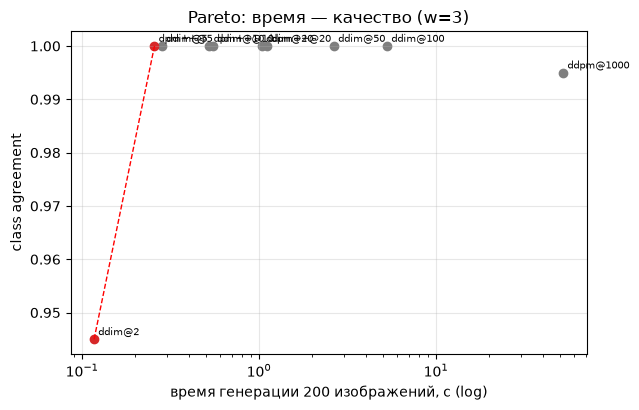

недоминируемые точки: ['ddim@2', 'dpm++@5']


In [8]:
import matplotlib.pyplot as plt
pts = {k: (v["seconds"], v["class_agreement"]) for k, v in bench.items()}
def dominated(p, q):     # q доминирует p: не медленнее и не хуже, и строго лучше хотя бы по одному
    return q[0] <= p[0] and q[1] >= p[1] and (q[0] < p[0] or q[1] > p[1])
pareto = sorted([k for k, p in pts.items() if not any(dominated(p, q) for kk, q in pts.items() if kk != k)], key=lambda k: pts[k][0])
save_json("pareto.json", {"objective": "min seconds, max class_agreement", "frontier": pareto, "points": pts})
plt.figure(figsize=(6.5, 4.2))
for k, (s, a) in pts.items():
    plt.scatter(s, a, c="tab:red" if k in pareto else "tab:gray"); plt.annotate(k, (s, a), fontsize=7, xytext=(3, 3), textcoords="offset points")
plt.plot([pts[k][0] for k in pareto], [pts[k][1] for k in pareto], "r--", lw=1)
plt.xscale("log"); plt.xlabel("время генерации 200 изображений, с (log)"); plt.ylabel("class agreement"); plt.grid(alpha=0.3)
plt.title("Pareto: время — качество (w=3)"); plt.tight_layout(); plt.savefig(ARTIFACTS / "pareto.png", dpi=120); plt.show()
print("недоминируемые точки:", pareto)

### Подготовка отдельного student

*Вес: 1 балл.*

**Постановка.** Student обучается на последовательных переходах teacher, а не на произвольной регрессии к фиксированному изображению. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Загрузите train MNIST и инициализируйте отдельную модель весами teacher.

**Результат.** Проверяемое состояние «Подготовка отдельного student» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Загрузите train MNIST и инициализируйте отдельную модель весами teacher» и его результат доступен следующему этапу.

In [9]:
import copy
from torch.utils.data import DataLoader, TensorDataset
mnist_train = torchvision.datasets.MNIST(DATA_ROOT, train=True, download=True)
X_train = mnist_train.data[:20000].float().div(127.5).sub(1).unsqueeze(1); y_train = mnist_train.targets[:20000]
student = copy.deepcopy(teacher).train()
for p in student.parameters():
    p.requires_grad = True
assert all(torch.equal(a, b) for a, b in zip(student.state_dict().values(), teacher.state_dict().values()))
assert {id(p) for p in student.parameters()}.isdisjoint({id(p) for p in teacher.parameters()})
print("student — отдельная копия teacher (EMA-веса работы 17); train MNIST:", tuple(X_train.shape))

student — отдельная копия teacher (EMA-веса работы 17); train MNIST: (20000, 1, 28, 28)


### Двухшаговые цели для distillation

*Вес: 1 балл.*

**Постановка.** Student обучается на последовательных переходах teacher, а не на произвольной регрессии к фиксированному изображению. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Оптимизируйте student по двум переходам замороженного teacher с checkpoint.

**Результат.** Проверяемое состояние «Двухшаговые цели для distillation» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Оптимизируйте student по двум переходам замороженного teacher с checkpoint» и его результат доступен следующему этапу.

In [10]:
TEACHER_STEPS, STUDENT_STEPS = 20, 10
DIST_STEPS = 2 if FAST_DEV_RUN else 3000
t_grid = ddim_grid(TEACHER_STEPS)                  # 20 точек; student шагает через одну

@torch.no_grad()
def teacher_two_steps(x, i, y):
    """Два DDIM-перехода teacher (с CFG) из t_grid[2i] в t_grid[2i+2] (или в −1)."""
    for j in (2 * i, 2 * i + 1):
        t = int(t_grid[j]); s = int(t_grid[j + 1]) if j + 1 < len(t_grid) else -1
        tt = torch.full((len(x),), t, device=DEVICE, dtype=torch.long)
        eps, _ = guided_eps(teacher, x, tt, y)
        a_t, a_s = ab_at(t).to(DEVICE), ab_at(s).to(DEVICE)
        x0 = ((x - (1 - a_t).sqrt() * eps) / a_t.sqrt()).clamp(-1, 1)
        eps = (x - a_t.sqrt() * x0) / (1 - a_t).sqrt()
        x = a_s.sqrt() * x0 + (1 - a_s).sqrt() * eps
    return x

def student_eps_target(x_t, x_target, t, s):
    """ε, при котором один DDIM-шаг student из t в s попадает ровно в x_target двух шагов teacher."""
    a_t, a_s = ab_at(t).to(DEVICE), ab_at(s).to(DEVICE)
    denom = (1 - a_s).sqrt() - (a_s / a_t).sqrt() * (1 - a_t).sqrt()
    return (x_target - (a_s / a_t).sqrt() * x_t) / denom

dist_path = ARTIFACTS / ("student_smoke.pt" if FAST_DEV_RUN else "student_10.pt")
opt = torch.optim.Adam(student.parameters(), lr=5e-5)
state = {"step": 0, "loss": []}
if dist_path.exists():
    dck = torch.load(dist_path, map_location=DEVICE, weights_only=False)
    student.load_state_dict(dck["model"]); opt.load_state_dict(dck["optimizer"]); state = dck["state"]
g = torch.Generator().manual_seed(SEED + state["step"])
t0 = time.time()
while state["step"] < DIST_STEPS:
    b = torch.randint(0, len(X_train), (64,), generator=g)
    x0, y = X_train[b].to(DEVICE), y_train[b].to(DEVICE)
    i = int(torch.randint(0, STUDENT_STEPS, (1,), generator=g))
    t = int(t_grid[2 * i]); s = int(t_grid[2 * i + 2]) if 2 * i + 2 < len(t_grid) else -1
    x_t = q_sample(x0, torch.full((64,), t, device=DEVICE), torch.randn(x0.shape, generator=g).to(DEVICE), sched)
    target = student_eps_target(x_t, teacher_two_steps(x_t, i, y), t, s)
    loss = F.mse_loss(student(x_t, torch.full((64,), t, device=DEVICE, dtype=torch.long), y), target)
    opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(student.parameters(), 1.0); opt.step()
    state["step"] += 1; state["loss"].append(loss.item())
    if state["step"] % 500 == 0 or state["step"] == DIST_STEPS:
        torch.save({"model": student.state_dict(), "optimizer": opt.state_dict(), "state": state,
                    "teacher_steps": TEACHER_STEPS, "student_steps": STUDENT_STEPS, "guidance_baked": GUIDANCE}, dist_path)
        print(f"distillation шаг {state['step']}/{DIST_STEPS}: loss {np.mean(state['loss'][-200:]):.4f} ({time.time() - t0:.0f} c)")
student.eval()
print(f"student обучен {state['step']} шагов: 20 шагов teacher (CFG w={GUIDANCE}) → 10 шагов student")

distillation шаг 500/3000: loss 0.0017 (40 c)


distillation шаг 1000/3000: loss 0.0008 (78 c)


distillation шаг 1500/3000: loss 0.0008 (116 c)


distillation шаг 2000/3000: loss 0.0021 (155 c)


distillation шаг 2500/3000: loss 0.0011 (193 c)


distillation шаг 3000/3000: loss 0.0006 (231 c)
student обучен 3000 шагов: 20 шагов teacher (CFG w=3.0) → 10 шагов student


### Сравнение при равных и разных NFE

*Вес: 1 балл.*

**Постановка.** Student обучается на последовательных переходах teacher, а не на произвольной регрессии к фиксированному изображению. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сравните teacher 20/10 и student 10 на общих noise/labels; сохраните изображения и время.

**Результат.** Проверяемое состояние «Сравнение при равных и разных NFE» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сравните teacher 20/10 и student 10 на общих noise/labels; сохраните изображения и время» и его результат доступен следующему этапу.

                 nfe_cond  nfe_uncond  nfe_total  seconds  class_agreement  mean_confidence  intra_class_l2_diversity
teacher_ddim_20      20.0        20.0       40.0   1.0356              1.0           0.9996                   16.2694
teacher_ddim_10      10.0        10.0       20.0   0.5209              1.0           0.9996                   15.5103
teacher_ddim_5        5.0         5.0       10.0   0.2605              1.0           0.9990                   13.6559
student_10           10.0         0.0       10.0   0.2814              1.0           0.9990                   16.0962


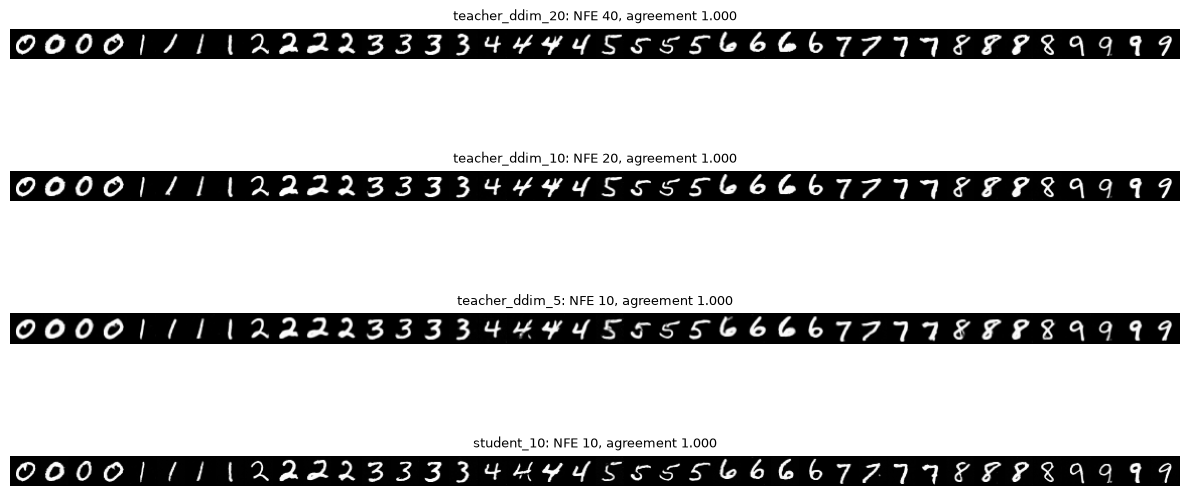

In [11]:
def student_eps(net, x, t, y):
    return net(x, t, y), {"cond": 1, "uncond": 0}     # guidance «зашит» в student — одна ветвь на шаг

@torch.no_grad()
def student_sample(net, x_T, y, steps=STUDENT_STEPS):
    """Шаги student — каждая вторая точка сетки teacher, затем переход в −1."""
    grid = ddim_grid(TEACHER_STEPS)[::TEACHER_STEPS // steps]
    x, y = x_T.to(DEVICE), y.to(DEVICE)
    for k, t in enumerate(grid.tolist()):
        s = grid[k + 1].item() if k + 1 < len(grid) else -1
        tt = torch.full((len(x),), t, device=DEVICE, dtype=torch.long)
        eps, _ = student_eps(net, x, tt, y)
        a_t, a_s = ab_at(t).to(DEVICE), ab_at(s).to(DEVICE)
        x0 = ((x - (1 - a_t).sqrt() * eps) / a_t.sqrt()).clamp(-1, 1)
        eps = (x - a_t.sqrt() * x0) / (1 - a_t).sqrt()
        x = a_s.sqrt() * x0 + (1 - a_s).sqrt() * eps
    return x.clamp(-1, 1).cpu(), {"cond": len(grid), "uncond": 0}

cmp = {}
for name, fn in [("teacher_ddim_20", lambda: ddim_sample(teacher, x_T, y_gen, 20)), ("teacher_ddim_10", lambda: ddim_sample(teacher, x_T, y_gen, 10)),
                 ("teacher_ddim_5", lambda: ddim_sample(teacher, x_T, y_gen, 5)), ("student_10", lambda: student_sample(student, x_T, y_gen))]:
    sync(); t0 = time.time(); imgs, nfe = fn(); sync(); sec = time.time() - t0
    imgs = save_png_grid(imgs, name)
    images[name] = imgs
    cmp[name] = {"nfe_cond": nfe["cond"], "nfe_uncond": nfe["uncond"], "nfe_total": nfe["cond"] + nfe["uncond"], "seconds": sec, **judge(imgs, y_gen)}
cmp["distillation"] = {"steps": state["step"], "final_loss": float(np.mean(state["loss"][-200:])), "lr": 5e-5, "batch": 64}
save_json("distillation_comparison.json", cmp)
print(pd.DataFrame({k: v for k, v in cmp.items() if k != "distillation"}).T.round(4).to_string())
fig, axes = plt.subplots(4, 1, figsize=(12, 6.5))
for ax, name in zip(axes, ["teacher_ddim_20", "teacher_ddim_10", "teacher_ddim_5", "student_10"]):
    sel = images[name].view(10, PER_CLASS, 1, 28, 28)[:, :4].reshape(-1, 1, 28, 28)
    ax.imshow(torchvision.utils.make_grid(sel.add(1).div(2), nrow=40, padding=1).permute(1, 2, 0)); ax.axis("off")
    ax.set_title(f"{name}: NFE {cmp[name]['nfe_total']}, agreement {cmp[name]['class_agreement']:.3f}", fontsize=9)
fig.tight_layout(); fig.savefig(ARTIFACTS / "teacher_vs_student.png", dpi=110); plt.show()

ошибок классификатора по конфигурациям: {'ddpm@1000': 1, 'ddim@100': 0, 'ddim@50': 0, 'ddim@20': 0, 'ddim@10': 0, 'ddim@5': 0, 'ddim@2': 11, 'dpm++@20': 0, 'dpm++@10': 0, 'dpm++@5': 0, 'teacher_ddim_20': 0, 'teacher_ddim_10': 0, 'teacher_ddim_5': 0, 'student_10': 0}
        config  index  target  pred  p_target  p_pred            type
0    ddpm@1000    140       7     3    0.3096  0.6674   misclassified
1      ddim@10    133       6     6    0.9806  0.9806  low_confidence
2      ddim@10     38       1     1    0.9968  0.9968  low_confidence
3      ddim@10     26       1     1    0.9975  0.9975  low_confidence
4       ddim@5    133       6     6    0.8503  0.8503  low_confidence
5       ddim@5     38       1     1    0.9968  0.9968  low_confidence
6       ddim@5     26       1     1    0.9968  0.9968  low_confidence
7       ddim@2     25       1     2    0.1933  0.4630   misclassified
8       ddim@2     26       1     3    0.0929  0.7775   misclassified
9       ddim@2     28       1    

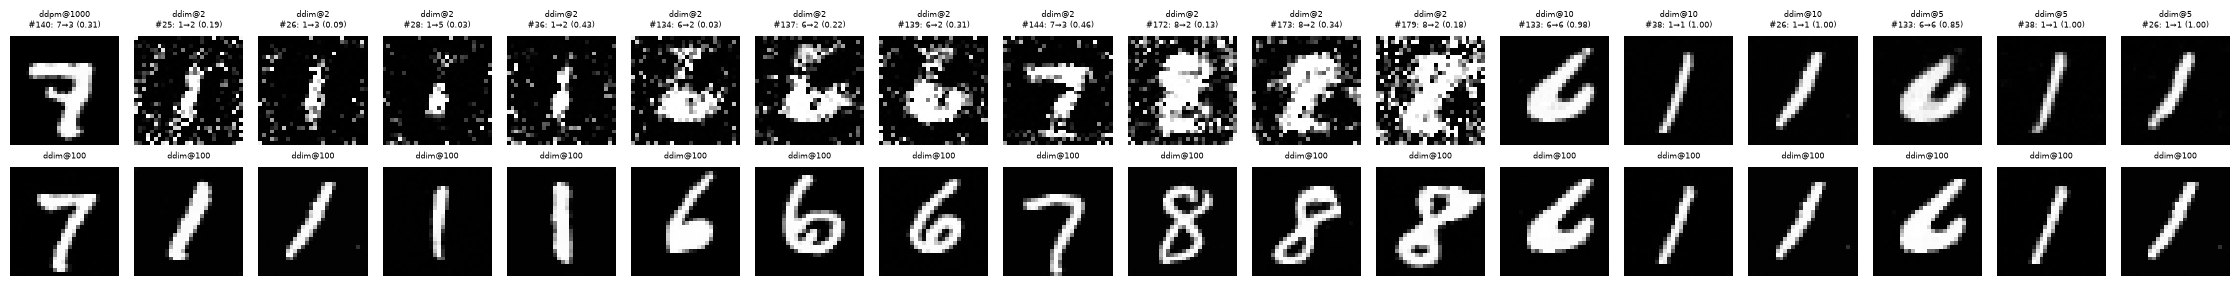

In [12]:
# Разбор неудач на общих noise/labels: все изображения, которые классификатор отнёс не к заданному классу,
# и по три самых неуверенных изображения у быстрых конфигураций без ошибок. Снизу — тот же шум после эталонной траектории.
@torch.no_grad()
def class_probs(imgs):
    return clf(imgs.to(DEVICE)).softmax(1).cpu()

by_name = {("{}@{}".format(*k) if isinstance(k, tuple) else k): v for k, v in images.items()}
ref_name = "ddim@100" if "ddim@100" in by_name else next(iter(by_name))
cases, n_wrong = [], {}
for name, imgs in by_name.items():
    p = class_probs(imgs)
    pred, p_target = p.argmax(1), p[torch.arange(len(p)), y_gen]
    wrong = torch.where(pred != y_gen)[0].tolist()
    n_wrong[name] = len(wrong)
    picked = [(i, "misclassified") for i in wrong]
    if not wrong and name in ("ddim@10", "ddim@5", "dpm++@5", "student_10"):
        picked = [(int(i), "low_confidence") for i in p_target.argsort()[:3]]
    for i, kind in picked:
        cases.append({"config": name, "index": i, "target": int(y_gen[i]), "pred": int(pred[i]), "p_target": round(float(p_target[i]), 4),
                      "p_pred": round(float(p[i].max()), 4), "type": kind})
save_json("error_cases.json", {"reference": ref_name, "misclassified_per_config": n_wrong, "cases": cases})
print("ошибок классификатора по конфигурациям:", n_wrong)
print(pd.DataFrame(cases).to_string())
show = [c for c in cases if c["type"] == "misclassified"][:12] + [c for c in cases if c["type"] == "low_confidence"][:6]
if show:
    fig, axes = plt.subplots(2, len(show), figsize=(1.25 * len(show), 3.0), squeeze=False)
    for j, c in enumerate(show):
        axes[0, j].imshow(by_name[c["config"]][c["index"], 0], cmap="gray", vmin=-1, vmax=1)
        axes[0, j].set_title(f"{c['config']}\n#{c['index']}: {c['target']}→{c['pred']} ({c['p_target']:.2f})", fontsize=6)
        axes[1, j].imshow(by_name[ref_name][c["index"], 0], cmap="gray", vmin=-1, vmax=1)
        axes[1, j].set_title(ref_name, fontsize=6)
    for ax in axes.flat:
        ax.axis("off")
    fig.tight_layout(); fig.savefig(ARTIFACTS / "error_cases.png", dpi=130); plt.show()

### Творческое мини-исследование

*Вес: 1 балл, бонус сверх десяти обязательных заданий.*

**Постановка.** Контролируемая абляция позволяет отделить влияние одного фактора от шума выборки. Гипотеза формулируется до просмотра отложенных результатов.

Выполните следующие действия:

1. Сформулируйте собственную предметную гипотезу о поведении модели и измените один фактор, сохраняя те же реальные входы, seed и вычислительный бюджет.
2. Сравните с основным экспериментом, не используя test для выбора настройки; объясните наблюдаемые расхождения.

**Результат.** Отдельные код, измеренная таблица и интерпретация в отчёте.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена на реальных входах, сохранены фактические измерения и показана контролируемая разница. Бонус не является обязательным для Run All.

## Анализ результатов

Сопоставьте конфигурации при одинаковых данных, seeds и бюджете. Приведите таблицу фактических метрик и времени, не менее пяти неудачных примеров с объяснением причин, ограничения и проверяемые выводы. Не подменяйте измерения утверждением об успешном запуске.

## Требования к сдаче

Перед сдачей перезапустите ядро и выполните все ячейки по порядку в полном режиме. Приложите конфигурацию, версии библиотек, источники/лицензии данных и модели, checkpoints, таблицу измерений, изображения и краткий анализ ошибок. Для длительного обучения перенесите каталог `artifacts/` на Google Drive и возобновляйте обучение с последнего checkpoint; отсутствие GPU или данных нельзя заменять синтетическими метриками.